# Supporting Figure S4

![Full Figure](../figures/suppS4_FULL.png)

## Code for Supporting Figure S4: exponential violation-history filter

**Goal:** Illustrate the exponential filter kernel and how filtered violation history resets at session boundaries.

| Panel | Content |
|---|---|
| A | Exponential filter kernel ($\tau = 4$) |
| B | Example filtered sessions (violations, filter trace, session boundaries) |

Simulated toy sessions only — no animal data loaded. Source styling from the Sept 2023 tau-search demo (`plot_kernel_validation` / `ExpFilter.plot_kernel` in `violations-multinomial`).

**Outputs:** `figures/suppS4a_exponential_kernel.png`, `figures/suppS4b_filtered_sequence.png`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from violations_glm.features import exponential_filter, exponential_kernel
from violations_glm.plotting import configure_publication_dpi, save_figure

configure_publication_dpi()
sns.set_context(
    "notebook",
    rc={
        "font.size": 16,
        "axes.titlesize": 18,
        "axes.labelsize": 16,
        "axes.titleweight": "bold",
        "xtick.labelsize": 14,
        "ytick.labelsize": 14,
        "legend.fontsize": 12,
    },
)

In [2]:
TAU = 4
SESSION_LENGTHS = (10, 7, 5)
# Hardcoded pattern matching the lab-meeting figure (sessions of length 10 / 7 / 5).
VIOLATION_TRIALS = {0, 3, 4, 10, 11, 12, 15, 17, 19, 20}

## Panel A — Exponential filter kernel

PosixPath('/Users/jessbreda/Documents/github/Breda-Violations-GLM-PLOSOne/figures/suppS4a_exponential_kernel.png')

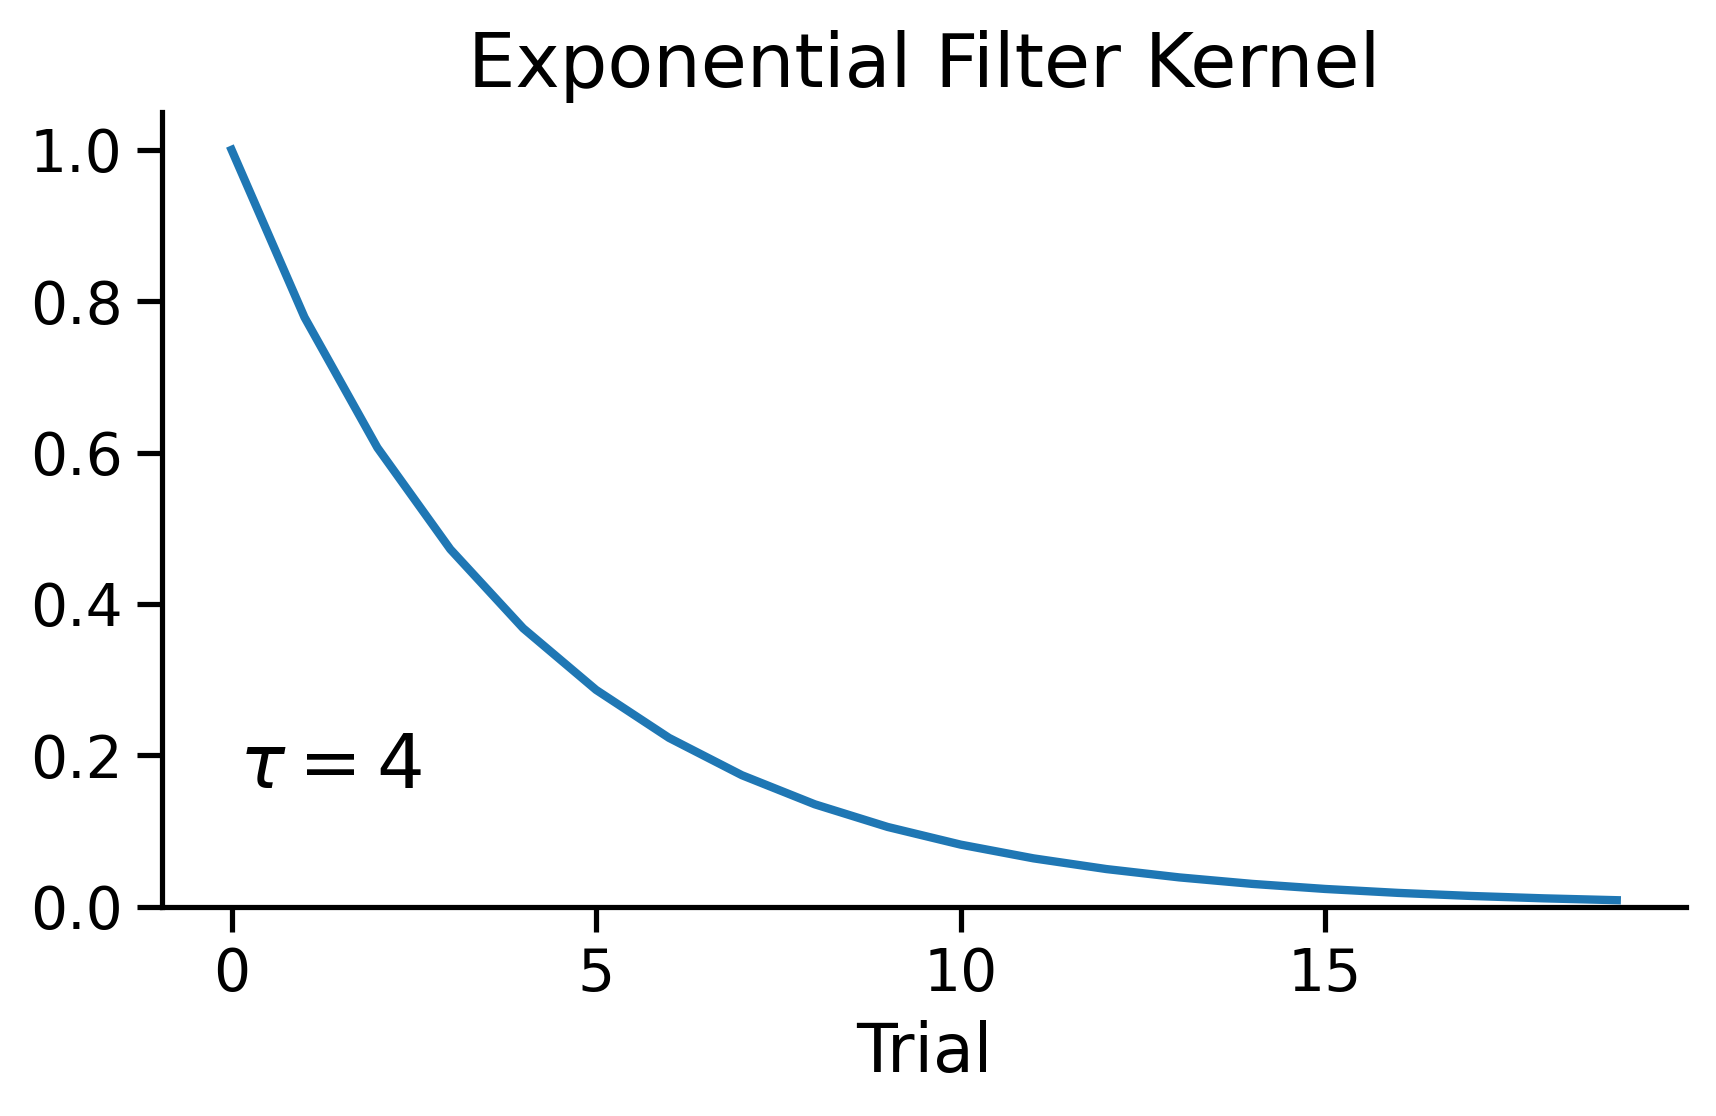

In [6]:
kernel = exponential_kernel(TAU)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(np.arange(len(kernel)), kernel, color="C0", lw=2)
ax.text(0.05, 0.15, rf"$\tau = {TAU}$",
        transform=ax.transAxes, fontsize=18, fontweight="bold")
ax.set(title="Exponential Filter Kernel", xlabel="Trial", ylim=(0, 1.05))
ax.set_yticks(np.arange(0, 1.1, 0.2))
sns.despine(ax=ax)
fig.tight_layout()
save_figure(fig, "suppS4a_exponential_kernel")

## Panel B — Example filtered sessions

Red vertical lines mark violations. The gray trace is the session-wise exponential filter of *previous* violation (max-scaled), matching the regressor used in the models. Dashed lines mark session boundaries, where the filter resets.

PosixPath('/Users/jessbreda/Documents/github/Breda-Violations-GLM-PLOSOne/figures/suppS4b_filtered_sequence.png')

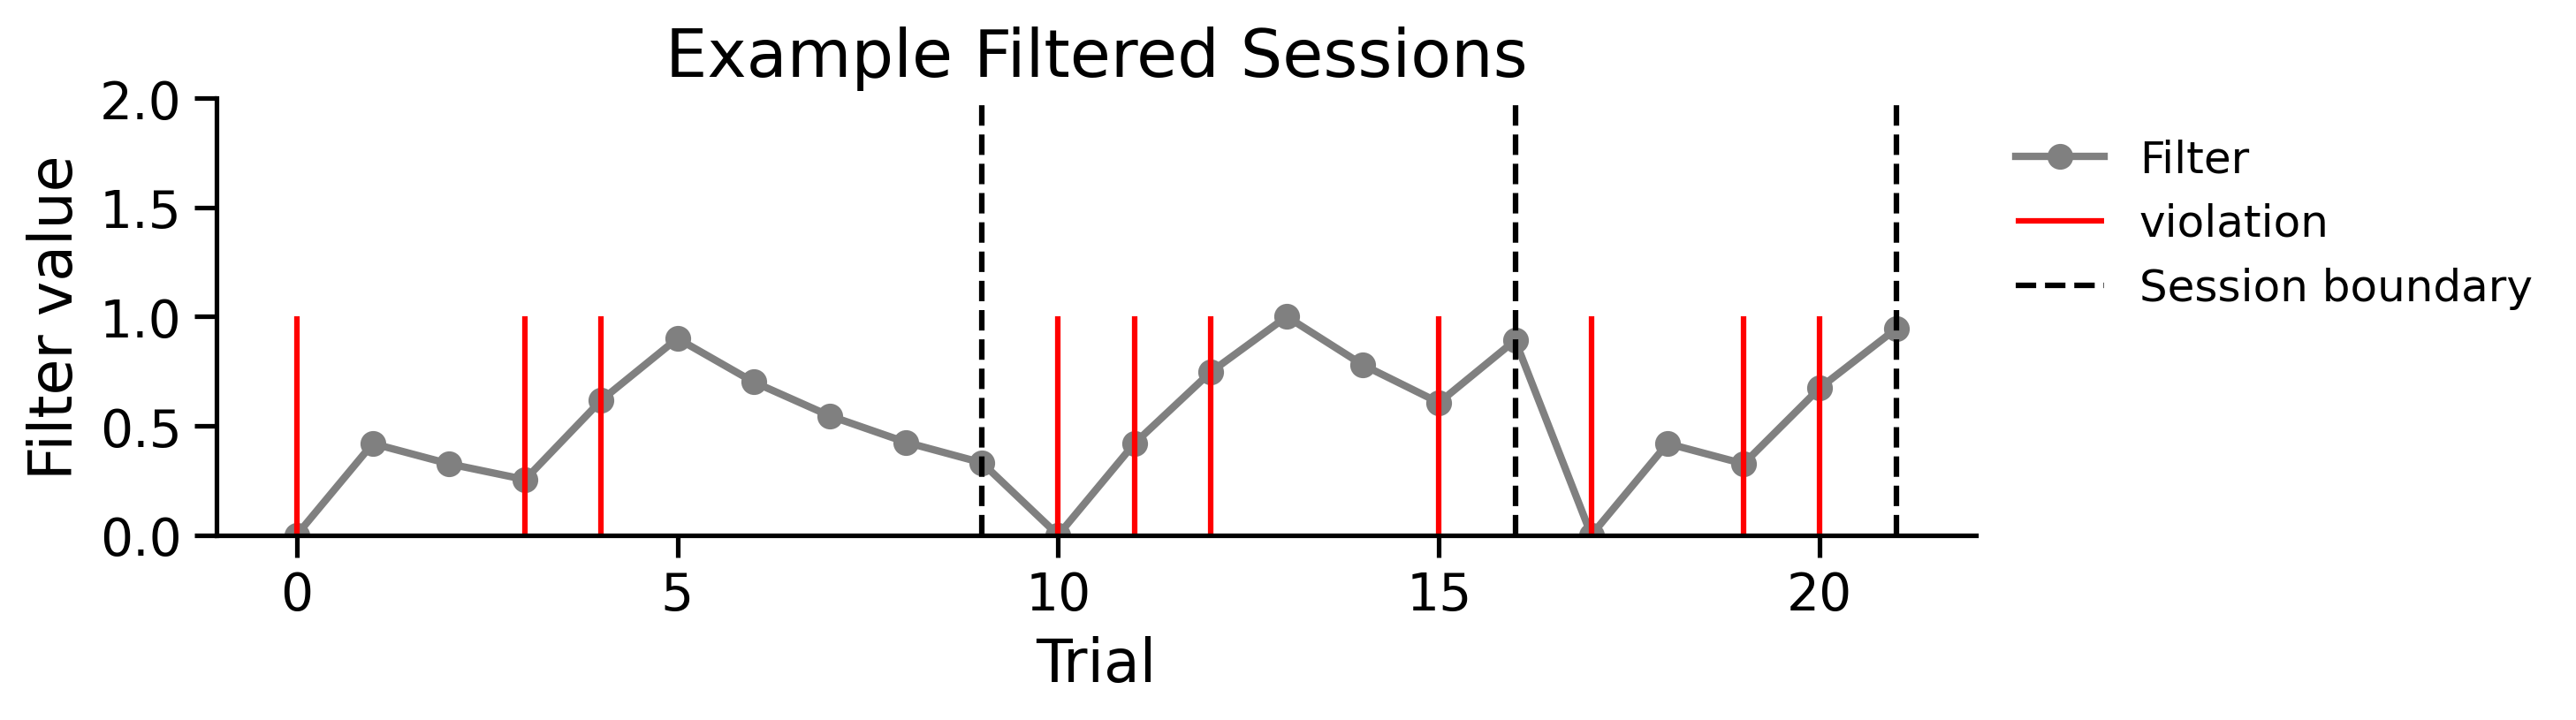

In [7]:
n_trials = sum(SESSION_LENGTHS)
sessions = np.repeat(np.arange(1, len(SESSION_LENGTHS) + 1), SESSION_LENGTHS)
violations = np.array(
    [1 if trial in VIOLATION_TRIALS else 0 for trial in range(n_trials)])
demo = pd.DataFrame({"session": sessions, "violation": violations})
session_mask = demo["session"].diff().eq(0)
demo["prev_violation"] = (demo["violation"].shift() * session_mask).fillna(0)
demo["filtered"] = exponential_filter(
    demo["prev_violation"], demo["session"], TAU)

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(
    demo.index,
    demo["filtered"],
    color="gray",
    marker="o",
    lw=2,
    label="Filter",
)
for idx, value in demo["violation"].items():
    if value == 1:
        ax.vlines(x=idx, ymin=0, ymax=1, color="r", label="violation")

last_idx_of_each_session = demo["session"].duplicated(keep="last")
for idx, is_duplicated in enumerate(last_idx_of_each_session):
    if not is_duplicated:
        ax.vlines(
            x=idx,
            ymin=0,
            ymax=2,
            color="k",
            linestyles="dashed",
            label="Session boundary",
        )

handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax.legend(by_label.values(), by_label.keys(),
          bbox_to_anchor=(1, 1), loc=2, frameon=False)
ax.set(
    title="Example Filtered Sessions",
    xlabel="Trial",
    ylabel="Filter value",
    ylim=(0, 2),
)
ax.set_yticks(np.arange(0, 2.5, 0.5))
sns.despine(ax=ax)
fig.tight_layout()
save_figure(fig, "suppS4b_filtered_sequence")